# Groww Stocks – Exploratory Data Analysis (EDA)
**Data:** `groww_cleaned_stocks.csv` (800 stocks scraped from groww.in; random sample of 5,987 listed instruments).
**Analysis set:** the 658 real companies that are actively traded and have fundamentals (`Analysis_Ready = True`).

**Questions**
1. How is the market structured by company size?
2. Which industries are biggest, and how are they valued?
3. How do profitability, dividends and risk change with size?
4. Who owns these companies?
5. How far have stocks fallen from their 52-week highs?
6. Which stocks pass a simple quality screen?

*A one-day snapshot for learning. Not investment advice.*

## 0. Setup

In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.titleweight": "bold"})
os.makedirs("charts", exist_ok=True)
NAVY, TEAL, AMBER, CORAL, RED, GREY = "#1F3A5F", "#2A9D8F", "#E9A23B", "#E76F51", "#C0392B", "#8D99AE"

df = pd.read_csv("groww_cleaned_stocks.csv")
a = df[df["Analysis_Ready"]].copy()
order = ["Micro", "Small", "Mid", "Large"]
a["Market_Cap_Category"] = pd.Categorical(a["Market_Cap_Category"], order, ordered=True)
print("All rows:", len(df), "| analysis-ready companies:", len(a))

All rows: 800 | analysis-ready companies: 658


## 1. Data overview

In [3]:
print(df["Instrument_Type"].value_counts().to_string(), "\n")
print(df["Trading_Status"].value_counts().to_string())
a[["Price","Market_Cap_Cr","PE_Ratio","ROE_pct","PB_Ratio","Debt_to_Equity","Promoters_pct","Institutional_Holding_pct"]].describe().round(2)

Instrument_Type
Equity    743
ETF        57 

Trading_Status
Active      715
Inactive     85


,Price,Market_Cap_Cr,PE_Ratio,ROE_pct,PB_Ratio,Debt_to_Equity,Promoters_pct,Institutional_Holding_pct
count,658.00,658.00,493.00,658.00,658.00,653.00,658.00,658.00
mean,395.93,7543.80,77.94,-9.16,4.45,0.43,52.44,5.82
std,1648.60,45610.88,347.77,380.42,19.88,2.93,21.48,12.34
min,0.14,0.06,0.02,-9527.55,0.00,-29.62,0.00,0.00
25%,19.51,28.00,11.97,0.99,0.68,0.01,41.39,0.00
50%,65.60,146.50,21.11,7.02,1.52,0.16,57.32,0.32
75%,242.50,1151.00,47.26,14.00,3.47,0.60,70.00,5.37
max,31415.00,914291.00,5858.00,713.18,426.14,49.18,99.36,92.32


## 2. Market structure by company size
Market-cap bands: **Micro** under ₹500 Cr, **Small** ₹500–5,000 Cr, **Mid** ₹5,000–20,000 Cr, **Large** over ₹20,000 Cr (approximate).

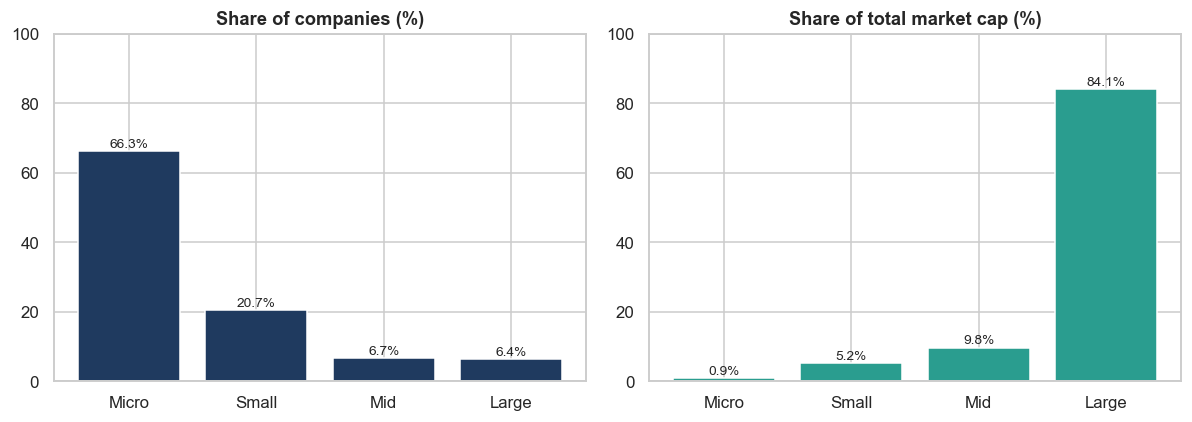

Top 10 companies hold 55.0% of the sample's market cap


,companies,market_cap,% of companies,% of market cap
Market_Cap_Category,,,,
Micro,436,43026.2,66.3,0.9
Small,136,259855.0,20.7,5.2
Mid,44,484291.0,6.7,9.8
Large,42,4176645.0,6.4,84.1


In [4]:
g = a.groupby("Market_Cap_Category", observed=True).agg(
    companies=("Company", "size"), market_cap=("Market_Cap_Cr", "sum"))
g["% of companies"] = g["companies"] / g["companies"].sum() * 100
g["% of market cap"] = g["market_cap"] / g["market_cap"].sum() * 100

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(g.index, g["% of companies"], color=NAVY)
ax[0].set_title("Share of companies (%)")
ax[1].bar(g.index, g["% of market cap"], color=TEAL)
ax[1].set_title("Share of total market cap (%)")
for x, y in zip(ax, ["% of companies", "% of market cap"]):
    for i, v in enumerate(g[y]):
        x.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=9)
    x.set_ylim(0, 100)
plt.tight_layout(); plt.savefig("charts/01_market_structure.png"); plt.show()
top10 = a.nlargest(10, "Market_Cap_Cr")["Market_Cap_Cr"].sum() / a["Market_Cap_Cr"].sum() * 100
print(f"Top 10 companies hold {top10:.1f}% of the sample's market cap")
g.round(1)

**Finding:** about two in three companies are micro caps but together hold under 1% of the value. The 42 large caps (6% of companies) hold about 84%, and the top 10 stocks alone hold 55%.

## 3. Industries: size and valuation

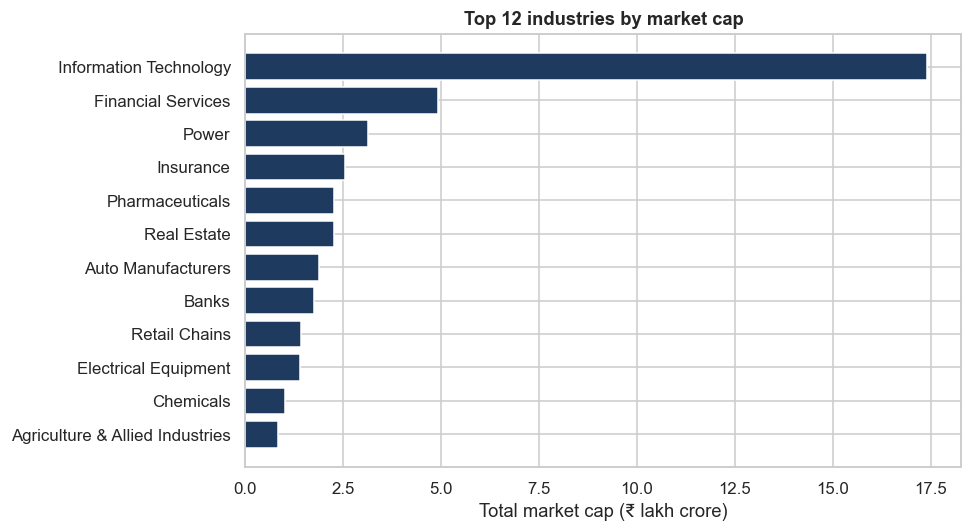

IT alone = 35.1% of total market cap


In [5]:
ind = a.groupby("Industry").agg(
    companies=("Company", "size"), market_cap=("Market_Cap_Cr", "sum"),
    median_pe=("PE_Ratio", "median"), industry_pe=("Industry_PE", "median"),
    median_roe=("ROE_pct", "median"), profitable=("Is_Profitable", "mean"),
    dividend_payers=("Pays_Dividend", "mean"), from_high=("Pct_From_52W_High", "median"))
top = ind.sort_values("market_cap", ascending=False).head(12)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top.index[::-1], top["market_cap"][::-1] / 1e5, color=NAVY)
ax.set_xlabel("Total market cap (₹ lakh crore)")
ax.set_title("Top 12 industries by market cap")
plt.tight_layout(); plt.savefig("charts/02_industry_market_cap.png"); plt.show()
share_it = ind.loc["Information Technology", "market_cap"] / ind["market_cap"].sum() * 100
print(f"IT alone = {share_it:.1f}% of total market cap")

In [ ]:
big = ind[ind["companies"] >= 10].sort_values("market_cap", ascending=False).head(12)
x = np.arange(len(big)); w = 0.4
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x - w/2, big["median_pe"], w, label="Median P/E of sampled companies", color=TEAL)
ax.bar(x + w/2, big["industry_pe"], w, label="Groww industry P/E", color=GREY)
ax.set_xticks(x); ax.set_xticklabels(big.index, rotation=40, ha="right")
ax.set_title("Valuation: sampled companies vs industry P/E (industries with 10+ companies)")
ax.legend(); plt.tight_layout(); plt.savefig("charts/03_pe_vs_industry.png"); plt.show()
cheaper = (a["PE_Ratio"] < a["Industry_PE"]).sum(); n = a["PE_Ratio"].notna().sum()
print(f"{cheaper} of {n} companies ({cheaper/n*100:.0f}%) trade at a P/E below their industry P/E")

**Finding:** IT is the largest industry by value (about 35% of the sample), followed by financial services, power, insurance and pharma. Most companies (about 65%) trade below their industry P/E, because the sample is mostly small companies that the market values lower than the large industry leaders.

## 4. Profitability, dividends and risk by size

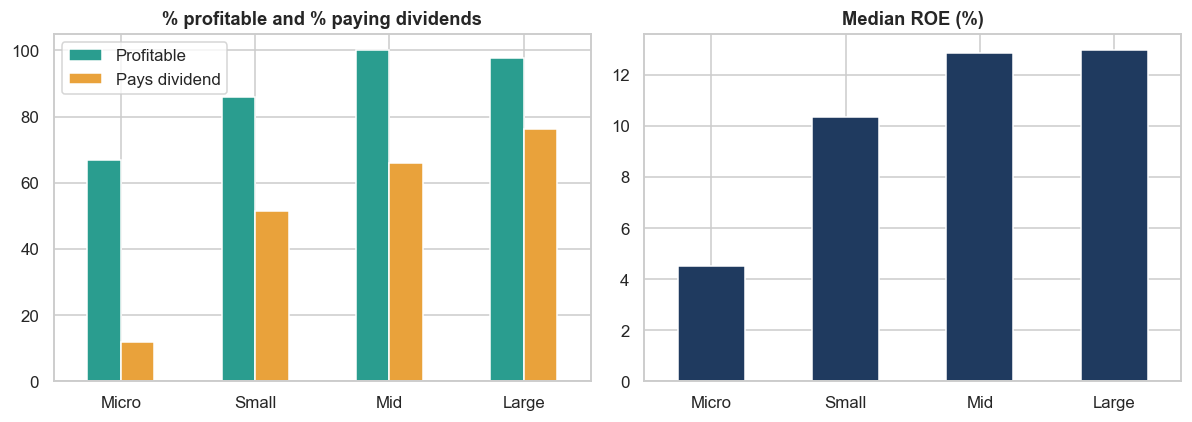

Loss-making companies: 165 (25%), of which 145 are micro caps
Debt-to-equity above 1: 85 companies


,profitable,dividend_payers,median_roe,median_pe,median_debt_equity
Market_Cap_Category,,,,,
Micro,0.67,0.12,4.53,17.65,0.13
Small,0.86,0.51,10.36,22.89,0.24
Mid,1.00,0.66,12.86,28.99,0.22
Large,0.98,0.76,12.96,35.81,0.29


In [6]:
q = a.groupby("Market_Cap_Category", observed=True).agg(
    profitable=("Is_Profitable", "mean"), dividend_payers=("Pays_Dividend", "mean"),
    median_roe=("ROE_pct", "median"), median_pe=("PE_Ratio", "median"),
    median_debt_equity=("Debt_to_Equity", "median"))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
q[["profitable", "dividend_payers"]].mul(100).plot(kind="bar", ax=ax[0], color=[TEAL, AMBER], rot=0)
ax[0].set_title("% profitable and % paying dividends"); ax[0].set_xlabel(""); ax[0].legend(["Profitable", "Pays dividend"])
q["median_roe"].plot(kind="bar", ax=ax[1], color=NAVY, rot=0)
ax[1].set_title("Median ROE (%)"); ax[1].set_xlabel("")
plt.tight_layout(); plt.savefig("charts/04_quality_by_size.png"); plt.show()
loss = a[a["Is_Profitable"] == 0]
print(f"Loss-making companies: {len(loss)} ({len(loss)/len(a)*100:.0f}%), of which {(loss['Market_Cap_Category']=='Micro').sum()} are micro caps")
print(f"Debt-to-equity above 1: {(a['Debt_to_Equity'] > 1).sum()} companies")
q.round(2)

**Finding:** quality rises steadily with size. Profitable companies go from 67% (micro) to about 98% (large); dividend payers from 12% to 76%; median ROE from 4.5% to about 13%. Of the 165 loss-making companies, 145 are micro caps.

## 5. Who owns these companies?

In [ ]:
own = a.groupby("Market_Cap_Category", observed=True)[["Promoters_pct", "DII_pct", "FII_pct", "Public_pct"]].mean()
own.plot(kind="bar", stacked=True, figsize=(8, 4.5), color=[NAVY, TEAL, AMBER, GREY], rot=0)
plt.title("Average shareholding pattern by company size (%)")
plt.ylabel("% of shares"); plt.xlabel(""); plt.legend(["Promoters", "DII", "FII", "Public"], bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.savefig("charts/05_shareholding.png"); plt.show()
own.round(1)

In [ ]:
a["Promoter_Band"] = pd.cut(a["Promoters_pct"], [-1, 25, 50, 75, 100], labels=["<25%", "25-50%", "50-75%", ">75%"])
a.groupby("Promoter_Band", observed=True).agg(companies=("Company", "size"), median_roe=("ROE_pct", "median"),
                                              profitable=("Is_Profitable", "mean")).round(2)

**Finding:** institutional ownership (DII + FII) grows from about 1% in micro caps to about 32% in large caps, while the public holds 48% of micro caps but 15% of large ones. Promoters hold around 50% in every size band. Companies where promoters hold under 25% tend to have lower ROE (about 2%, versus about 9% at 50–75%), but this is a tendency, not proof.

## 6. Momentum: distance from the 52-week high

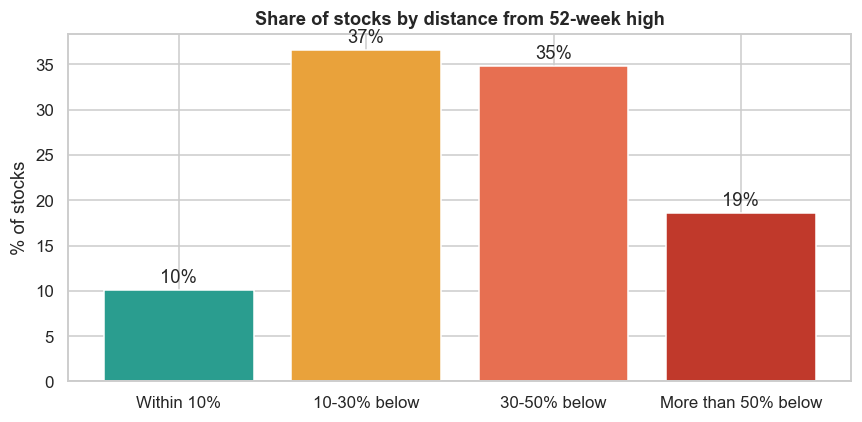

53% are more than 30% below their 52-week high


Industry
Power                   -51.9
Media & Entertainment   -46.2
Healthcare              -42.1
Distributors            -39.6
Infrastructure          -36.6
Name: from_high, dtype: float64

In [7]:
d = a["Pct_From_52W_High"].dropna()
bins = pd.cut(d, [-100, -50, -30, -10, 10], labels=["More than 50% below", "30-50% below", "10-30% below", "Within 10%"])
b = bins.value_counts().reindex(["Within 10%", "10-30% below", "30-50% below", "More than 50% below"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(b.index, b.values / b.sum() * 100, color=[TEAL, AMBER, CORAL, RED])
for i, v in enumerate(b.values / b.sum() * 100):
    ax.text(i, v + 0.8, f"{v:.0f}%", ha="center")
ax.set_title("Share of stocks by distance from 52-week high"); ax.set_ylabel("% of stocks")
plt.tight_layout(); plt.savefig("charts/06_distance_from_high.png"); plt.show()
print(f"{(d < -30).mean()*100:.0f}% are more than 30% below their 52-week high")
ind[ind["companies"] >= 10]["from_high"].sort_values().head(5).round(1)

**Finding:** about half the stocks (53% of those with 52-week data) are more than 30% below their 52-week high and only about 10% are within 10% of it. Power, media and healthcare are the weakest industries on this measure.

## 7. Correlations

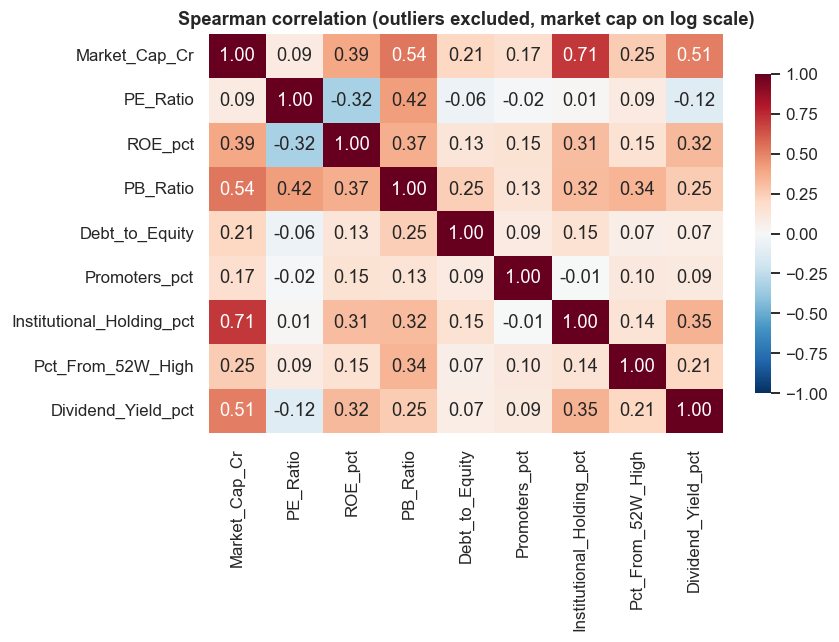

In [8]:
cols = ["Market_Cap_Cr", "PE_Ratio", "ROE_pct", "PB_Ratio", "Debt_to_Equity", "Promoters_pct",
        "Institutional_Holding_pct", "Pct_From_52W_High", "Dividend_Yield_pct"]
clean = a[~a["Flag_Outlier"]][cols].copy()
clean["Market_Cap_Cr"] = np.log10(clean["Market_Cap_Cr"])
corr = clean.corr(method="spearman")
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, cbar_kws={"shrink": .8})
plt.title("Spearman correlation (outliers excluded, market cap on log scale)")
plt.tight_layout(); plt.savefig("charts/07_correlation.png"); plt.show()

**Finding:** the strongest link is between market cap and institutional holding (about 0.7): big companies attract institutions. Market cap also moves with price-to-book (0.5) and dividend yield (0.5).

## 8. A simple quality screen (learning example)
Criteria: ROE above 15%, debt-to-equity below 0.5, profitable, P/E below industry P/E, market cap at least ₹500 Cr, no outlier flag.

In [9]:
screen = a[(a["ROE_pct"] > 15) & (a["Debt_to_Equity"] < 0.5) & (a["Is_Profitable"] == 1) &
           (a["PE_Ratio"] < a["Industry_PE"]) & (a["Market_Cap_Cr"] >= 500) & (~a["Flag_Outlier"])]
print(len(screen), "of", len(a), "companies pass")
screen.sort_values("Market_Cap_Cr", ascending=False)[
    ["Company", "Industry", "Market_Cap_Cr", "PE_Ratio", "Industry_PE", "ROE_pct", "Debt_to_Equity", "Promoters_pct"]].head(15).round(2)

31 of 658 companies pass


,Company,Industry,Market_Cap_Cr,PE_Ratio,Industry_PE,ROE_pct,Debt_to_Equity,Promoters_pct
293,Infosys,Information Technology,473763.0,15.62,17.46,33.24,0.10,13.82
772,Wipro,Information Technology,186816.0,14.13,17.46,16.68,0.28,72.58
412,Hero MotoCorp,Auto Manufacturers,103273.0,18.82,24.10,26.57,0.04,34.72
493,AIA Engineering,Engineering,33465.0,26.46,50.66,15.83,0.00,58.50
770,The Great Eastern Shipping Company,Maritime Industries,21508.0,5.74,8.64,17.35,0.06,30.07
500,Castrol India,Chemicals,19392.0,18.25,38.19,55.65,0.03,51.00
431,Bayer CropScience,Agriculture & Allied Industries,15453.0,21.11,25.11,23.24,0.03,71.43
736,Chambal Fertilisers and Chemicals,Agriculture & Allied Industries,15251.0,7.91,21.22,18.77,0.10,61.72
253,National Securities Depository,Financial Services,14656.0,37.71,41.75,16.02,0.01,0.00
476,International Gemological Institute,Professional Services,13844.0,22.70,36.19,38.34,0.10,76.55


**Finding:** 31 companies pass all six rules, mostly mid-to-large firms in IT, auto, engineering and agriculture. This is a research starting point, not a recommendation.

## 9. Summary of insights
1. **Concentration:** 42 large caps hold about 84% of the sample's value; two in three companies are micro caps with under 1%.
2. **Size = quality:** profitability, dividends, ROE and institutional ownership all rise with size.
3. **Risk sits in micro caps:** 145 of 165 loss-making companies are micro caps.
4. **IT dominates value** (about 35%); financial services has the most companies (82) but mostly tiny ones.
5. **Most stocks are well below their highs:** 53% are more than 30% under the 52-week high.
6. **Valuation:** about 65% of companies trade below their industry P/E, but a low P/E is not automatically good value.
7. **Listing matters:** companies with an NSE symbol have a median market cap of about ₹994 Cr against ₹31 Cr for those without one, with about 10% institutional holding versus about 1%.

**Limits:** one-day snapshot; random sample of 800 of 5,987 instruments (13%); no historical returns; P/E and ROE for micro caps can be extreme.